# 05 · Ruta de la patrulla con A* y BFS (Hugo)

La patrulla sale de una comisaría, pasa por los puntos críticos del distrito (de `03_riesgo`) y vuelve.

* **Distritos:** los de peligrosidad media y alta (sección 1). Cercado de Lima y San Juan de Lurigancho siguen siendo los pilotos para las comprobaciones, la comparación con BFS y las figuras.
* **Grafo:** calles del distrito; esquina = nodo, tramo = arista dirigida (respeta los sentidos únicos).
* **Costo:** `largo / (1 + β·riesgo)`. Una calle riesgosa «cuesta menos», así la patrulla pasa por donde más se necesita. Con β = 0 es la ruta más corta.
* **Heurística:** `distancia en línea recta / (1 + β)`. Como el riesgo está entre 0 y 1, nunca sobreestima y A* encuentra la mejor ruta.
* **BFS:** verifica que todo sea alcanzable y sirve de comparación.

Entradas: `data/osm/`, `data/processed/riesgo_calles.csv`, `data/processed/puntos_criticos.csv`.
Salidas: `outputs/mapas/ruta_*.html`, `outputs/figuras/rutas_pilotos.png` y `data/processed/rutas_resumen.csv`.

In [1]:
import os
import sys
import time
import heapq
import json
from collections import deque, defaultdict
from itertools import chain, permutations
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import folium
import matplotlib.pyplot as plt
from shapely.geometry import LineString

os.environ.setdefault("PATRULLA_OSM", "local")
sys.path.insert(0, "../src")
import fuente_osm as fuente
ox = fuente.ox

PROCESADOS = fuente.RAIZ / "data" / "processed"
MAPAS = fuente.RAIZ / "outputs" / "mapas"
FIGURAS = fuente.RAIZ / "outputs" / "figuras"
PILOTOS = ["150101", "150132"]   # comprobaciones, comparación y figuras
NIVELES_CON_RUTA = ["medio", "alto"]  # distritos que reciben ruta
BETA = 2.0          # cuánto prefiere la patrulla las calles riesgosas
BETAS_COMPARAR = [0.0, 1.0, 2.0, 5.0]
print("Fuente:", fuente.fuente())
assert not fuente.es_mock(), "Con datos simulados se sobrescribirían los resultados reales"

Fuente: local


## 1. Datos

**Peligrosidad del distrito:** denuncias esperadas el mes siguiente (`02_prediccion`) por km², dividida en tercios: bajo, medio y alto. En los distritos de nivel bajo casi ninguna calle tiene factores de riesgo (su riesgo medio es cercano a 0), así que sus «puntos críticos» serían esquinas cualesquiera; por eso solo los niveles medio y alto reciben ruta.

In [2]:
limites = fuente.cargar_limites()
G_lima = fuente.cargar_calles()

riesgo_csv = pd.read_csv(PROCESADOS / "riesgo_calles.csv", usecols=["u", "v", "RIESGO"])
# riesgo_calles.csv no tiene dirección: se busca por el par {u, v}; si hay tramos paralelos, el mayor
riesgo_par = riesgo_csv.assign(par=[frozenset(p) for p in zip(riesgo_csv.u, riesgo_csv.v)]).groupby("par")["RIESGO"].max().to_dict()
puntos = pd.read_csv(PROCESADOS / "puntos_criticos.csv", dtype={"UBIGEO": str})

# Peligrosidad del distrito: denuncias esperadas por km², en tercios
pred = pd.read_csv(PROCESADOS / "prediccion_distritos.csv", dtype={"UBIGEO": str})
areas = pd.read_csv(PROCESADOS / "areas_distritos.csv", dtype={"UBIGEO": str})
nivel = pred.merge(areas[["UBIGEO", "DIST_NORM", "AREA_KM2"]], on="UBIGEO")
nivel["DENSIDAD"] = nivel["D_ESPERADAS"] / nivel["AREA_KM2"]
nivel["NIVEL"] = pd.qcut(nivel["DENSIDAD"], 3, labels=["bajo", "medio", "alto"]).astype(str)
nivel["CON_RUTA"] = nivel["NIVEL"].isin(NIVELES_CON_RUTA)
nivel[["UBIGEO", "DIST_NORM", "DENSIDAD", "NIVEL", "CON_RUTA"]].round(3).to_csv(PROCESADOS / "peligrosidad_distritos.csv", index=False)
DISTRITOS = sorted(nivel.loc[nivel["CON_RUTA"], "UBIGEO"])
assert set(PILOTOS) <= set(DISTRITOS) and set(DISTRITOS) <= set(puntos["UBIGEO"])
print(nivel["NIVEL"].value_counts().to_string())
print("Distritos con ruta:", len(DISTRITOS))

lugares_osm = gpd.read_file(fuente.carpeta() / "lugares.geojson")
comisarias = lugares_osm[(lugares_osm["amenity"] == "police") &
                         lugares_osm["name"].fillna("").str.contains("comisar", case=False) &
                         ~lugares_osm["name"].fillna("").str.contains("familia", case=False)]  # las «de la familia» atienden violencia familiar, no patrullan
print("Comisarías con ese nombre en Lima:", len(comisarias))

NIVEL
bajo     15
alto     14
medio    14
Distritos con ruta: 28
Comisarías con ese nombre en Lima: 123


In [3]:
nodos_lima = ox.graph_to_gdfs(G_lima, edges=False)["geometry"]

def grafo_piloto(ubigeo):
    poligono = limites.loc[limites["UBIGEO"] == ubigeo, "geometry"].iloc[0]
    # Lo mismo que ox.truncate.truncate_graph_polygon(..., truncate_by_edge=True): las esquinas dentro del
    # distrito y las de afuera que tocan alguna de adentro. Se arma como subgrafo para no copiar
    # el grafo de toda Lima en cada distrito (con muchos distritos el proceso se caía).
    dentro = set(nodos_lima.index[nodos_lima.sindex.query(poligono, predicate="intersects")])
    borde = {v for n in dentro for v in chain(G_lima.successors(n), G_lima.predecessors(n))}
    g = G_lima.subgraph(dentro | borde).copy()
    g = ox.truncate.largest_component(g, strongly=True)  # se puede ir y volver entre cualquier par
    sin_riesgo = 0
    for a, b, d in g.edges(data=True):
        d["riesgo"] = riesgo_par.get(frozenset((a, b)))
        if d["riesgo"] is None:
            d["riesgo"], sin_riesgo = 0.0, sin_riesgo + 1
    assert all(0 <= d["riesgo"] <= 1 for *_, d in g.edges(data=True))
    return g, poligono, sin_riesgo

grafos = {}
for u in DISTRITOS:
    g, poligono, sin_riesgo = grafo_piloto(u)
    grafos[u] = (g, poligono)
    print(f"{u}: {g.number_of_nodes()} esquinas, {g.number_of_edges()} tramos dirigidos, sin riesgo: {sin_riesgo}")

150101: 2610 esquinas, 5563 tramos dirigidos, sin riesgo: 0


150103: 9170 esquinas, 24267 tramos dirigidos, sin riesgo: 0
150104: 423 esquinas, 788 tramos dirigidos, sin riesgo: 0
150105: 519 esquinas, 919 tramos dirigidos, sin riesgo: 0
150108: 3807 esquinas, 10254 tramos dirigidos, sin riesgo: 0


150110: 6319 esquinas, 17075 tramos dirigidos, sin riesgo: 0
150111: 1450 esquinas, 3891 tramos dirigidos, sin riesgo: 0
150112: 1988 esquinas, 5104 tramos dirigidos, sin riesgo: 0
150113: 563 esquinas, 1017 tramos dirigidos, sin riesgo: 0
150115: 1496 esquinas, 3173 tramos dirigidos, sin riesgo: 0
150116: 420 esquinas, 779 tramos dirigidos, sin riesgo: 0


150117: 3440 esquinas, 8957 tramos dirigidos, sin riesgo: 0
150120: 397 esquinas, 721 tramos dirigidos, sin riesgo: 0
150121: 918 esquinas, 1817 tramos dirigidos, sin riesgo: 0
150122: 1438 esquinas, 2861 tramos dirigidos, sin riesgo: 0
150128: 1297 esquinas, 3102 tramos dirigidos, sin riesgo: 0
150130: 1453 esquinas, 3365 tramos dirigidos, sin riesgo: 0
150131: 1419 esquinas, 2836 tramos dirigidos, sin riesgo: 0


150132: 14251 esquinas, 37923 tramos dirigidos, sin riesgo: 0
150133: 4064 esquinas, 10983 tramos dirigidos, sin riesgo: 0
150134: 603 esquinas, 1284 tramos dirigidos, sin riesgo: 0


150135: 7875 esquinas, 21271 tramos dirigidos, sin riesgo: 0
150136: 1434 esquinas, 3341 tramos dirigidos, sin riesgo: 0
150137: 1459 esquinas, 3714 tramos dirigidos, sin riesgo: 0


150140: 3970 esquinas, 9270 tramos dirigidos, sin riesgo: 0
150141: 907 esquinas, 1961 tramos dirigidos, sin riesgo: 0


150142: 6476 esquinas, 17020 tramos dirigidos, sin riesgo: 0


150143: 6776 esquinas, 18476 tramos dirigidos, sin riesgo: 0


## 2. Comisaría de salida y puntos a visitar
Se usa la comisaría (nombre con «Comisaría», sin las «de la familia»; ver `docs/revision_osm.md`) más cercana al centro de los puntos críticos. Hay que confirmarla con la lista de la PNP. Cada punto se ubica en la esquina más cercana del grafo; si dos puntos (o un punto y la comisaría) caen en la misma esquina, se visita una sola vez.

In [4]:
def preparar(ubigeo):
    g, poligono = grafos[ubigeo]
    p = puntos[puntos["UBIGEO"] == ubigeo].sort_values("ORDEN")
    candidatas = comisarias[comisarias.within(poligono)].copy()
    centro_lat, centro_lon = p["LAT"].mean(), p["LON"].mean()
    candidatas["d"] = ox.distance.great_circle(candidatas.geometry.y, candidatas.geometry.x, centro_lat, centro_lon)
    salida = candidatas.sort_values("d").iloc[0]
    nodo_salida = ox.distance.nearest_nodes(g, salida.geometry.x, salida.geometry.y)
    nodos_puntos = [int(n) for n in ox.distance.nearest_nodes(g, p["LON"].values, p["LAT"].values)]
    nodos_puntos = list(dict.fromkeys(n for n in nodos_puntos if n != nodo_salida))  # sin esquinas repetidas
    return salida["name"], int(nodo_salida), nodos_puntos

paradas = {u: preparar(u) for u in DISTRITOS}
for u, (nombre, salida, nodos_p) in paradas.items():
    print(f"{u}: sale de «{nombre}» | {len(nodos_p)} puntos críticos")

150101: sale de «Comisaría PNP Cotabambas» | 8 puntos críticos
150103: sale de «Comisaría PNP Vitarte» | 8 puntos críticos
150104: sale de «Comisaría PNP Barranco» | 8 puntos críticos
150105: sale de «Comisaría Chacra Colorada» | 8 puntos críticos
150108: sale de «Comisaría PNP Villa Chorrillos» | 8 puntos críticos
150110: sale de «Comisaría PNP Universitaria» | 8 puntos críticos
150111: sale de «Comisaría PNP Villa Hermosa» | 8 puntos críticos
150112: sale de «Comisaría PNP Independencia» | 8 puntos críticos
150113: sale de «Comisaría PNP Jesús María» | 8 puntos críticos
150115: sale de «Comisaría PNP La Victoria Apolo» | 8 puntos críticos
150116: sale de «Comisaría PNP Lince» | 8 puntos críticos
150117: sale de «Comisaría PNP Laura Caller Iberico» | 8 puntos críticos
150120: sale de «Comisaría PNP Magdalena» | 8 puntos críticos
150121: sale de «Comisaría PNP Pueblo Libre» | 8 puntos críticos
150122: sale de «Comisaría PNP Miraflores» | 7 puntos críticos
150128: sale de «Comisaría PNP

## 3. BFS (programado por nosotros)
Recorre el grafo por niveles. Sirve para (a) verificar que desde la comisaría se llegue a todos los puntos y que se pueda volver, y (b) comparar: BFS encuentra el camino con **menos tramos**, no el más corto ni el más seguro.

In [5]:
def vecinos(g, beta):
    """Lista de adyacencia con el costo de cada tramo; si hay tramos paralelos, el más barato."""
    adj = defaultdict(dict)
    for a, b, d in g.edges(data=True):
        costo = d["length"] / (1 + beta * d["riesgo"])
        if costo < adj[a].get(b, (np.inf,))[0]:
            adj[a][b] = (costo, d["length"])
    return adj

def bfs(adj, inicio, meta=None):
    padre = {inicio: None}
    cola = deque([inicio])
    expandidos = 0
    while cola:
        n = cola.popleft()
        expandidos += 1
        if n == meta:
            break
        for v in adj[n]:
            if v not in padre:
                padre[v] = n
                cola.append(v)
    if meta is None:
        return set(padre), expandidos
    camino = [meta]
    while padre[camino[-1]] is not None:
        camino.append(padre[camino[-1]])
    return camino[::-1], expandidos

for u, (nombre, salida, nodos_p) in paradas.items():
    g = grafos[u][0]
    ida, _ = bfs(vecinos(g, 0), salida)
    vuelta, _ = bfs(vecinos(g.reverse(), 0), salida)
    print(f"{u}: alcanzables desde la comisaría {len(ida)}/{len(g)} | todos los puntos de ida: {set(nodos_p) <= ida} | de vuelta: {set(nodos_p) <= vuelta}")
    assert set(nodos_p) <= ida and set(nodos_p) <= vuelta

150101: alcanzables desde la comisaría 2610/2610 | todos los puntos de ida: True | de vuelta: True


150103: alcanzables desde la comisaría 9170/9170 | todos los puntos de ida: True | de vuelta: True
150104: alcanzables desde la comisaría 423/423 | todos los puntos de ida: True | de vuelta: True
150105: alcanzables desde la comisaría 519/519 | todos los puntos de ida: True | de vuelta: True
150108: alcanzables desde la comisaría 3807/3807 | todos los puntos de ida: True | de vuelta: True


150110: alcanzables desde la comisaría 6319/6319 | todos los puntos de ida: True | de vuelta: True
150111: alcanzables desde la comisaría 1450/1450 | todos los puntos de ida: True | de vuelta: True
150112: alcanzables desde la comisaría 1988/1988 | todos los puntos de ida: True | de vuelta: True
150113: alcanzables desde la comisaría 563/563 | todos los puntos de ida: True | de vuelta: True
150115: alcanzables desde la comisaría 1496/1496 | todos los puntos de ida: True | de vuelta: True
150116: alcanzables desde la comisaría 420/420 | todos los puntos de ida: True | de vuelta: True


150117: alcanzables desde la comisaría 3440/3440 | todos los puntos de ida: True | de vuelta: True
150120: alcanzables desde la comisaría 397/397 | todos los puntos de ida: True | de vuelta: True
150121: alcanzables desde la comisaría 918/918 | todos los puntos de ida: True | de vuelta: True
150122: alcanzables desde la comisaría 1438/1438 | todos los puntos de ida: True | de vuelta: True
150128: alcanzables desde la comisaría 1297/1297 | todos los puntos de ida: True | de vuelta: True
150130: alcanzables desde la comisaría 1453/1453 | todos los puntos de ida: True | de vuelta: True
150131: alcanzables desde la comisaría 1419/1419 | todos los puntos de ida: True | de vuelta: True


150132: alcanzables desde la comisaría 14251/14251 | todos los puntos de ida: True | de vuelta: True
150133: alcanzables desde la comisaría 4064/4064 | todos los puntos de ida: True | de vuelta: True
150134: alcanzables desde la comisaría 603/603 | todos los puntos de ida: True | de vuelta: True


150135: alcanzables desde la comisaría 7875/7875 | todos los puntos de ida: True | de vuelta: True
150136: alcanzables desde la comisaría 1434/1434 | todos los puntos de ida: True | de vuelta: True
150137: alcanzables desde la comisaría 1459/1459 | todos los puntos de ida: True | de vuelta: True
150140: alcanzables desde la comisaría 3970/3970 | todos los puntos de ida: True | de vuelta: True
150141: alcanzables desde la comisaría 907/907 | todos los puntos de ida: True | de vuelta: True


150142: alcanzables desde la comisaría 6476/6476 | todos los puntos de ida: True | de vuelta: True
150143: alcanzables desde la comisaría 6776/6776 | todos los puntos de ida: True | de vuelta: True


## 4. A* (programado por nosotros)
`f(n) = g(n) + h(n)`: costo acumulado más heurística. La heurística es la distancia en línea recta sobre la Tierra (la misma fórmula con la que osmnx mide el largo de las calles) dividida entre (1 + β). Un tramo nunca es más corto que la recta entre sus extremos y su costo es al menos `largo/(1+β)`, así que la heurística **es admisible y consistente**: A* devuelve la ruta óptima.

In [6]:
def heuristica(g, meta, beta):
    nodos = list(g.nodes)
    lat = np.array([g.nodes[n]["y"] for n in nodos]); lon = np.array([g.nodes[n]["x"] for n in nodos])
    recta = ox.distance.great_circle(lat, lon, g.nodes[meta]["y"], g.nodes[meta]["x"])
    return dict(zip(nodos, recta / (1 + beta)))

def a_estrella(adj, inicio, meta, h):
    mejor = {inicio: 0.0}
    padre = {inicio: None}
    abiertos = [(h[inicio], 0.0, inicio)]
    cerrados = set()
    expandidos = 0
    while abiertos:
        _, costo, n = heapq.heappop(abiertos)
        if n in cerrados:
            continue
        cerrados.add(n)
        expandidos += 1
        if n == meta:
            break
        for v, (c, _) in adj[n].items():
            nuevo = costo + c
            if nuevo < mejor.get(v, np.inf):
                mejor[v], padre[v] = nuevo, n
                heapq.heappush(abiertos, (nuevo + h[v], nuevo, v))
    camino = [meta]
    while padre[camino[-1]] is not None:
        camino.append(padre[camino[-1]])
    return camino[::-1], mejor[meta], expandidos

def largo_camino(adj, camino):
    return sum(adj[a][b][1] for a, b in zip(camino, camino[1:]))

In [7]:
# Comprobaciones: A* da el mismo costo que networkx y la heurística nunca sobreestima
u0 = PILOTOS[0]
g0 = grafos[u0][0]
_, salida0, nodos0 = paradas[u0]
for beta in [0.0, BETA]:
    adj = vecinos(g0, beta)
    h = heuristica(g0, nodos0[0], beta)
    _, costo, _ = a_estrella(adj, salida0, nodos0[0], h)
    peso = lambda a, b, d, beta=beta: min(e["length"] / (1 + beta * e["riesgo"]) for e in d.values())
    exacto = nx.shortest_path_length(g0, salida0, nodos0[0], weight=peso)
    real = nx.single_source_dijkstra_path_length(g0.reverse(), nodos0[0], weight=peso)
    sobreestima = sum(h[n] > real[n] + 1e-6 for n in real)
    print(f"β={beta}: A* {costo:.3f} | networkx {exacto:.3f} | nodos donde h sobreestima: {sobreestima}")
    assert abs(costo - exacto) < 1e-6 and sobreestima == 0

β=0.0: A* 3620.872 | networkx 3620.872 | nodos donde h sobreestima: 0
β=2.0: A* 2362.411 | networkx 2362.411 | nodos donde h sobreestima: 0


## 5. Orden de visita
Se calcula con A* el costo entre cada par de paradas (comisaría + 8 puntos = 72 búsquedas). Con 8 puntos se pueden probar **todos** los órdenes (8! = 40 320) y quedarse con el de menor costo total, ida y vuelta a la comisaría.

In [8]:
def mejor_recorrido(ubigeo, beta):
    g = grafos[ubigeo][0]
    _, salida, nodos_p = paradas[ubigeo]
    paradas_ = [salida] + nodos_p
    adj = vecinos(g, beta)
    costo, camino = {}, {}
    for j in paradas_:
        h = heuristica(g, j, beta)
        for i in paradas_:
            if i != j:
                camino[i, j], costo[i, j], _ = a_estrella(adj, i, j, h)
    mejor = min(permutations(nodos_p),
                key=lambda orden: sum(costo[a, b] for a, b in zip((salida,) + orden, orden + (salida,))))
    secuencia = (salida,) + mejor + (salida,)
    ruta = [salida]
    for a, b in zip(secuencia, secuencia[1:]):
        ruta += camino[a, b][1:]
    return ruta, secuencia, adj

def describir(g, adj, ruta, beta):
    tramos = list(zip(ruta, ruta[1:]))
    largos = np.array([adj[a][b][1] for a, b in tramos])
    riesgos = np.array([min(g[a][b].values(), key=lambda d: d["length"] / (1 + beta * d["riesgo"]))["riesgo"] for a, b in tramos])
    return {"km": largos.sum() / 1000, "riesgo_medio": np.average(riesgos, weights=largos),
            "% km en calles de riesgo > 0,5": 100 * largos[riesgos > 0.5].sum() / largos.sum()}

resultados, rutas = [], {}
for u in DISTRITOS:
    for beta in BETAS_COMPARAR:
        t = time.perf_counter()
        ruta, secuencia, adj = mejor_recorrido(u, beta)
        rutas[u, beta] = (ruta, secuencia)
        resultados.append({"UBIGEO": u, "beta": beta, **describir(grafos[u][0], adj, ruta, beta), "segundos": time.perf_counter() - t})
resumen = pd.DataFrame(resultados).round(3)
resumen.to_csv(PROCESADOS / "rutas_resumen.csv", index=False)
resumen[resumen["UBIGEO"].isin(PILOTOS)]

,UBIGEO,beta,km,riesgo_medio,"% km en calles de riesgo > 0,5",segundos
0,150101,0.0,19.310,0.466,50.227,0.055
1,150101,1.0,19.562,0.522,54.338,0.060
2,150101,2.0,19.603,0.523,54.224,0.065
3,150101,5.0,19.835,0.535,55.393,0.063
72,150132,0.0,18.341,0.442,33.325,0.134
73,150132,1.0,18.762,0.518,43.777,0.203
74,150132,2.0,18.854,0.522,45.660,0.211
75,150132,5.0,19.845,0.558,49.277,0.215


## 6. A* frente a BFS (y frente a A* sin heurística)
Para cada tramo del recorrido (comisaría → punto → punto → … → comisaría) con β = 2 se cuentan los nodos que revisa cada algoritmo y el tiempo. «A* sin heurística» (h = 0) es el algoritmo de Dijkstra: muestra cuánto ahorra la heurística.

In [9]:
filas = []
for u in PILOTOS:
    g = grafos[u][0]
    adj = vecinos(g, BETA)
    _, secuencia = rutas[u, BETA]
    cero = defaultdict(float)
    for a, b in zip(secuencia, secuencia[1:]):
        h = heuristica(g, b, BETA)
        for nombre, buscar in [("A*", lambda: a_estrella(adj, a, b, h)),
                               ("A* sin heurística (Dijkstra)", lambda: a_estrella(adj, a, b, cero)),
                               ("BFS", lambda: bfs(adj, a, b))]:
            t = time.perf_counter()
            salida_ = buscar()
            camino, expandidos = salida_[0], salida_[-1]
            filas.append({"UBIGEO": u, "algoritmo": nombre, "nodos revisados": expandidos,
                          "ms": (time.perf_counter() - t) * 1000, "metros": largo_camino(adj, camino),
                          "costo": sum(adj[x][y][0] for x, y in zip(camino, camino[1:]))})
comparacion = (pd.DataFrame(filas).groupby(["UBIGEO", "algoritmo"], sort=False)
               [["nodos revisados", "ms", "metros", "costo"]].sum().round(1))
comparacion

nodos revisados    ms   metros    costo
UBIGEO algoritmo                                                            
150101 A*                                       1267   1.3  19603.4  11303.1
       A* sin heurística (Dijkstra)             2332   2.0  19603.4  11303.1
       BFS                                      2627   0.7  19884.9  12847.0
150132 A*                                       3633   4.5  18854.1  10496.3
       A* sin heurística (Dijkstra)            11506  11.9  18854.1  10496.3
       BFS                                     13255   4.4  22031.4  12500.3

## 7. Mapas

In [10]:
def coordenadas(g, ruta, beta):
    puntos_ = []
    for a, b in zip(ruta, ruta[1:]):
        d = min(g[a][b].values(), key=lambda e: e["length"] / (1 + beta * e["riesgo"]))
        if "geometry" in d:
            xy = list(d["geometry"].coords)
            if xy[0] != (g.nodes[a]["x"], g.nodes[a]["y"]):
                xy = xy[::-1]
        else:
            xy = [(g.nodes[a]["x"], g.nodes[a]["y"]), (g.nodes[b]["x"], g.nodes[b]["y"])]
        puntos_ += xy if not puntos_ else xy[1:]
    return puntos_

for u in PILOTOS:
    g = grafos[u][0]
    nombre, salida, _ = paradas[u]
    _, secuencia = rutas[u, BETA]
    mapa = folium.Map(location=[g.nodes[salida]["y"], g.nodes[salida]["x"]], zoom_start=14, tiles="OpenStreetMap")
    for beta, color, guiones, etiqueta in [(0.0, "#555555", "8", "Ruta más corta (β = 0)"), (BETA, "#d62728", None, f"Ruta con riesgo (β = {BETA:g})")]:
        xy = coordenadas(g, rutas[u, beta][0], beta)
        folium.PolyLine([(y, x) for x, y in xy], color=color, weight=5, opacity=0.8, dash_array=guiones, tooltip=etiqueta).add_to(mapa)
    for i, n in enumerate(secuencia[1:-1], 1):
        folium.CircleMarker([g.nodes[n]["y"], g.nodes[n]["x"]], radius=8, color="#e4572e", fill=True, fill_opacity=1,
                            tooltip=f"Punto crítico, visita {i}").add_to(mapa)
    folium.Marker([g.nodes[salida]["y"], g.nodes[salida]["x"]], tooltip=f"Salida: {nombre}",
                  icon=folium.Icon(color="blue", icon="info-sign")).add_to(mapa)
    mapa.save(MAPAS / f"ruta_{u}.html")
print("Mapas guardados en outputs/mapas/")

Mapas guardados en outputs/mapas/


### Rutas para la web
Para cada distrito con ruta se guardan la comisaría, los puntos en el orden de visita y el trazado con β = 0 y β = 2 en `data/processed/rutas_distritos.json`. La web los dibuja y permite hacer clic sobre las calles para ver su riesgo.

In [11]:
def a_latlon(xy):
    return [[round(y, 5), round(x, 5)] for x, y in xy]

web = {}
for u in DISTRITOS:
    g = grafos[u][0]
    nombre, salida, nodos_p = paradas[u]
    p = puntos[puntos["UBIGEO"] == u].sort_values("ORDEN")
    riesgo_nodo = {}
    for n, r in zip(ox.distance.nearest_nodes(g, p["LON"].values, p["LAT"].values), p["RIESGO"]):
        riesgo_nodo[int(n)] = max(r, riesgo_nodo.get(int(n), 0.0))
    _, secuencia = rutas[u, BETA]
    web[u] = {
        "comisaria": nombre,
        "salida": [round(g.nodes[salida]["y"], 5), round(g.nodes[salida]["x"], 5)],
        "puntos": [{"visita": i, "lat": round(g.nodes[n]["y"], 5), "lon": round(g.nodes[n]["x"], 5), "riesgo": float(riesgo_nodo[n])}
                   for i, n in enumerate(secuencia[1:-1], 1)],
        "rutas": {f"{b:g}": a_latlon(coordenadas(g, rutas[u, b][0], b)) for b in (0.0, BETA)},
    }
with open(PROCESADOS / "rutas_distritos.json", "w", encoding="utf-8") as f:
    json.dump(web, f, ensure_ascii=False, separators=(",", ":"))
print("Rutas guardadas:", len(web), "distritos")


Rutas guardadas: 28 distritos


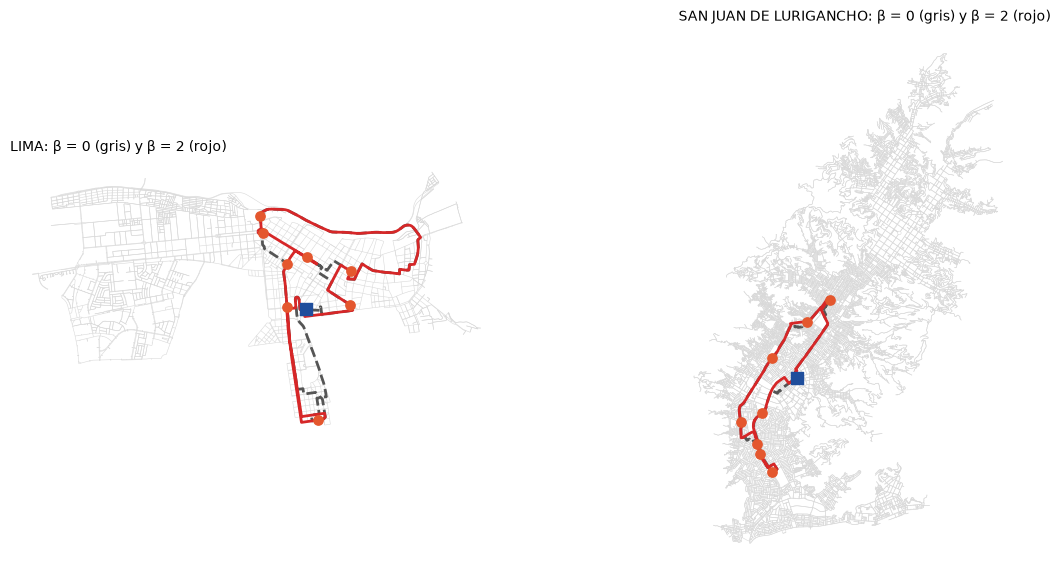

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 7))
for eje, u in zip(ejes, PILOTOS):
    g = grafos[u][0]
    ox.graph_to_gdfs(g, nodes=False).plot(ax=eje, color="#d9d9d9", linewidth=0.4)
    for beta, color, estilo in [(0.0, "#555555", "--"), (BETA, "#d62728", "-")]:
        xy = coordenadas(g, rutas[u, beta][0], beta)
        gpd.GeoSeries([LineString(xy)]).plot(ax=eje, color=color, linewidth=2, linestyle=estilo)
    _, secuencia = rutas[u, BETA]
    eje.scatter([g.nodes[n]["x"] for n in secuencia[1:-1]], [g.nodes[n]["y"] for n in secuencia[1:-1]], color="#e4572e", s=45, zorder=3)
    eje.scatter(g.nodes[secuencia[0]]["x"], g.nodes[secuencia[0]]["y"], color="#1f4e9c", marker="s", s=70, zorder=4)
    eje.set_title(f"{limites.set_index('UBIGEO').loc[u, 'DIST_NORM']}: β = 0 (gris) y β = {BETA:g} (rojo)", loc="left", fontsize=10)
    eje.set_axis_off()
plt.savefig(FIGURAS / "rutas_pilotos.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Lectura y limitaciones
* Al subir β, la ruta se alarga pero pasa más tiempo por calles de riesgo alto: es la decisión que controla la policía.
* A* revisa muchos menos nodos que Dijkstra gracias a la heurística; BFS revisa pocos, pero su camino (menos tramos) no es el más corto ni el más seguro.
* La comisaría de salida sale de OSM y debe verificarse con la lista de la PNP.
* Los distritos de peligrosidad baja no reciben ruta: sus calles casi no tienen factores de riesgo y los puntos serían arbitrarios.
* No se considera el tráfico vehicular ni la hora del día: OSM no los tiene.